In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)


In [3]:
train_values = pd.read_csv("train_values.csv")
train_labels = pd.read_csv("train_labels.csv")
display(train_values.head())
display(train_labels.head())

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0


,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


In [4]:
df = pd.merge(train_values,train_labels,on="building_id",how="inner")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,3


In [10]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn Names:")
print(df.columns.tolist())
df.info()
display(df.describe().T)
missing_values = df.isnull().sum()
print("Missing Values:")
#print(missing_values[missing_values > 0])
print("Total Missing Values:",df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)
display(df.dtypes)

Rows: 260601
Columns: 40

Column Names:
['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'legal_ownership_status', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_go

,count,mean,std,min,25%,50%,75%,max
building_id,260601.0,525675.482773,304544.999032,4.0,261190.0,525757.0,789762.0,1052934.0
geo_level_1_id,260601.0,13.900353,8.033617,0.0,7.0,12.0,21.0,30.0
geo_level_2_id,260601.0,701.074685,412.710734,0.0,350.0,702.0,1050.0,1427.0
geo_level_3_id,260601.0,6257.876148,3646.369645,0.0,3073.0,6270.0,9412.0,12567.0
count_floors_pre_eq,260601.0,2.129723,0.727665,1.0,2.0,2.0,2.0,9.0
age,260601.0,26.535029,73.565937,0.0,10.0,15.0,30.0,995.0
area_percentage,260601.0,8.018051,4.392231,1.0,5.0,7.0,9.0,100.0
height_percentage,260601.0,5.434365,1.918418,2.0,4.0,5.0,6.0,32.0
has_superstructure_adobe_mud,260601.0,0.088645,0.284231,0.0,0.0,0.0,0.0,1.0
has_superstructure_mud_mortar_stone,260601.0,0.761935,0.425900,0.0,1.0,1.0,1.0,1.0


Missing Values:
Total Missing Values: 0
Duplicate Rows: 0
Shape after removing duplicates: (260601, 40)


,0
building_id,int64
geo_level_1_id,int64
geo_level_2_id,int64
geo_level_3_id,int64
count_floors_pre_eq,int64
age,int64
area_percentage,int64
height_percentage,int64
land_surface_condition,object
foundation_type,object


damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


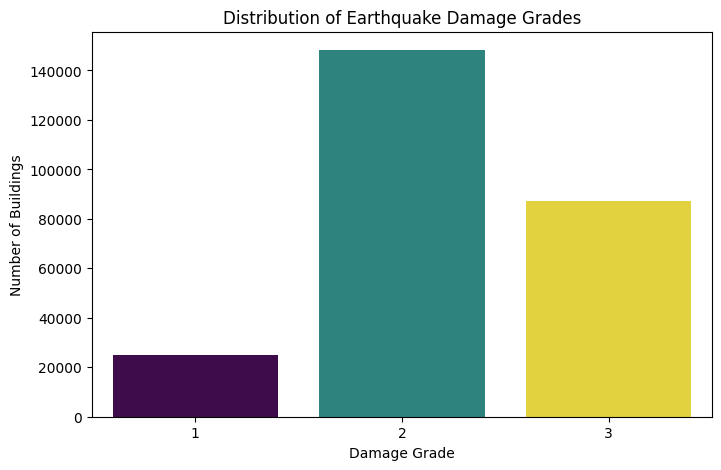

In [11]:
print(df["damage_grade"].value_counts().sort_index())
plt.figure(figsize=(8, 5))
sns.countplot(data=df,x="damage_grade",hue="damage_grade",palette="viridis",legend=False)
plt.title("Distribution of Earthquake Damage Grades")
plt.xlabel("Damage Grade")
plt.ylabel("Number of Buildings")
plt.show()

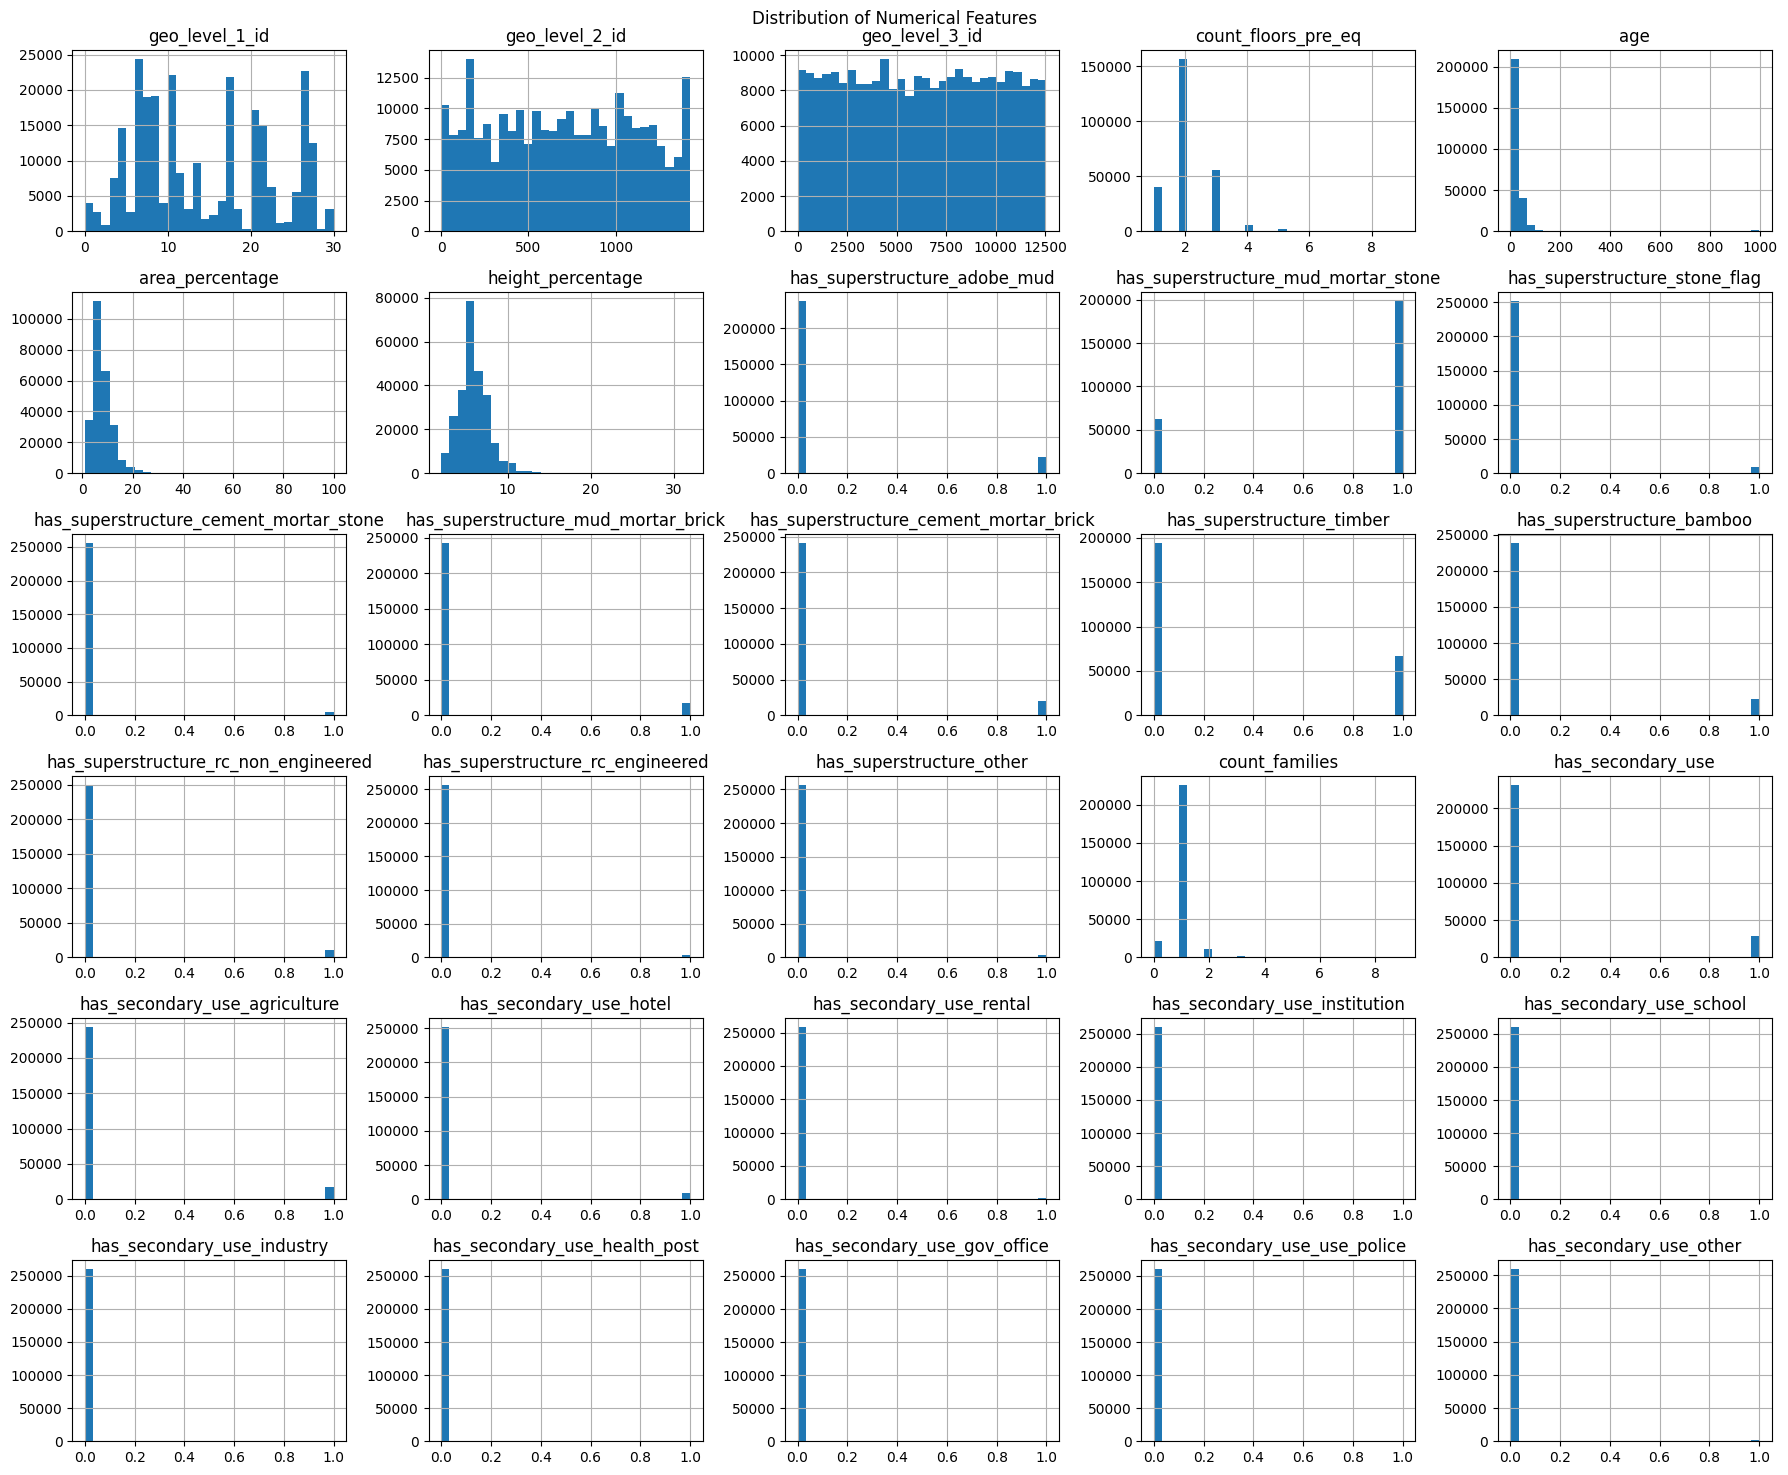

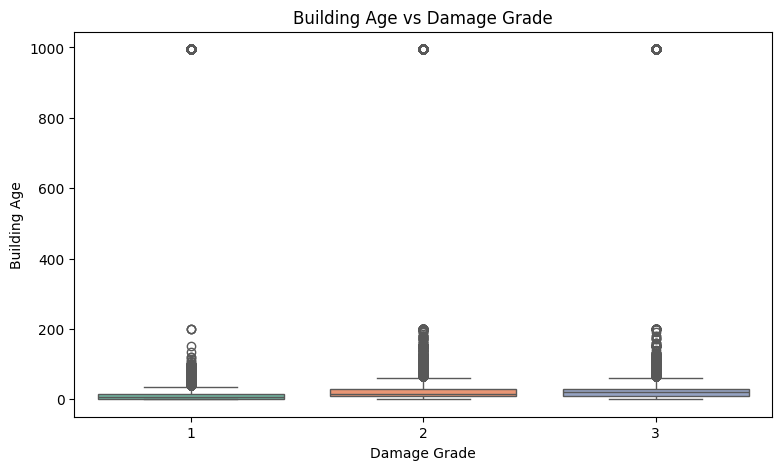

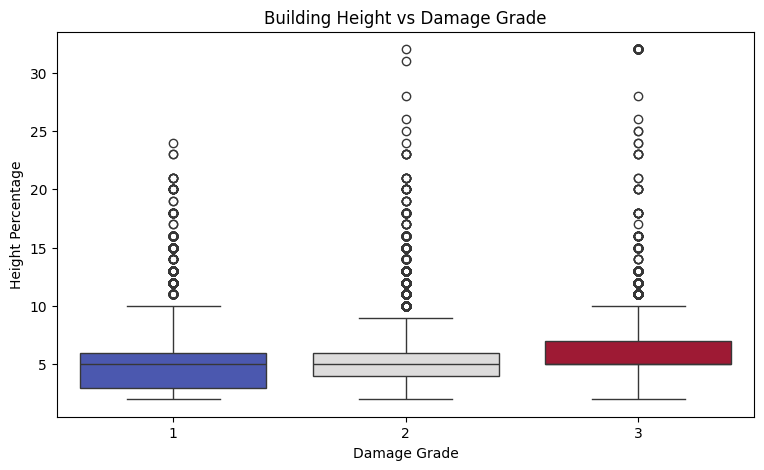

In [12]:
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
numerical_features = [col for col in numerical_features if col not in ["building_id", "damage_grade"]]
df[numerical_features].hist(figsize=(18, 15),bins=30)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df,x="damage_grade",y="age",hue="damage_grade",palette="Set2",legend=False)
plt.title("Building Age vs Damage Grade")
plt.xlabel("Damage Grade")
plt.ylabel("Building Age")
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df,x="damage_grade",y="height_percentage",hue="damage_grade",palette="coolwarm",legend=False)
plt.title("Building Height vs Damage Grade")
plt.xlabel("Damage Grade")
plt.ylabel("Height Percentage")
plt.show()

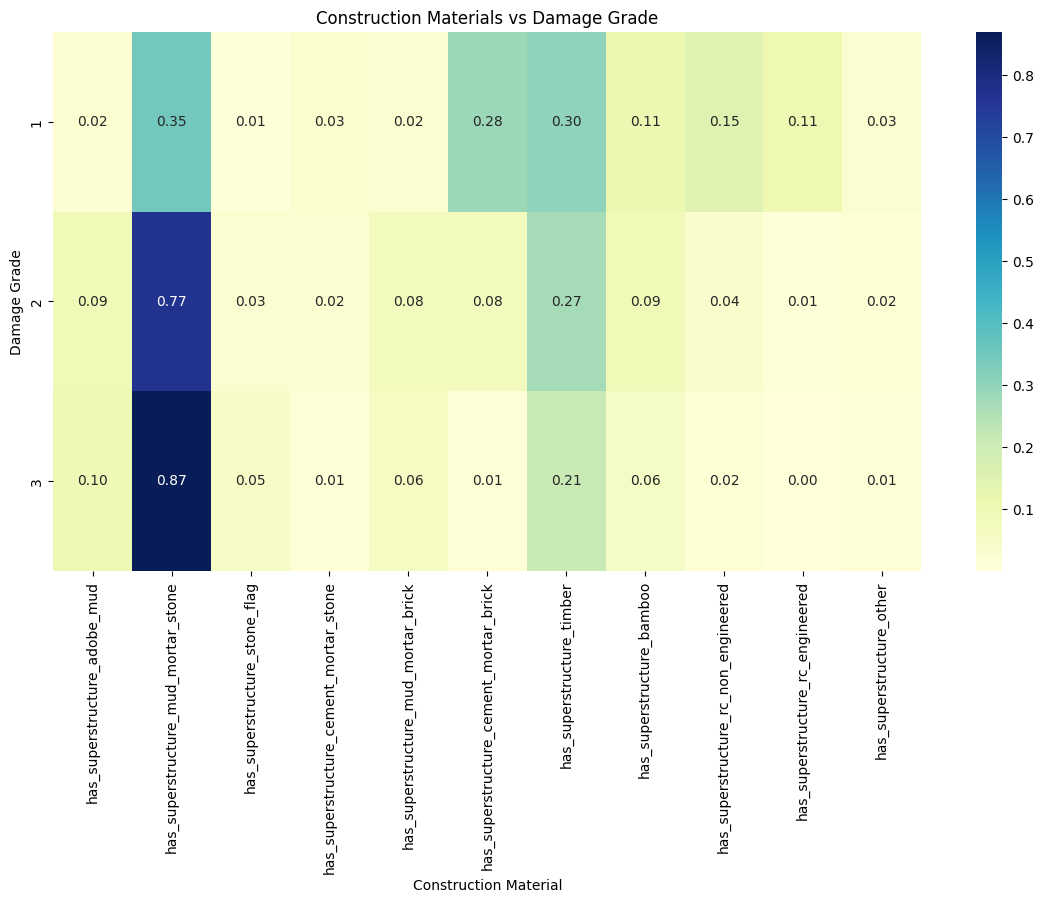

In [14]:
material_columns = [col for col in df.columns if col.startswith("has_superstructure_")]
material_damage = df.groupby("damage_grade")[material_columns].mean()
plt.figure(figsize=(14, 7))
sns.heatmap(material_damage,annot=True,cmap="YlGnBu",fmt=".2f")
plt.title("Construction Materials vs Damage Grade")
plt.xlabel("Construction Material")
plt.ylabel("Damage Grade")
plt.xticks(rotation=90)
plt.show()

In [15]:
X = df.drop(columns=["damage_grade", "building_id"])
y = df["damage_grade"]
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (260601, 38)
y Shape: (260601,)


In [16]:
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Numerical Features:", len(numerical_columns))
print("Categorical Features:", len(categorical_columns))
print("\nCategorical Columns:")
print(categorical_columns)

Numerical Features: 30
Categorical Features: 8

Categorical Columns:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']


In [17]:
numerical_transformer = Pipeline(steps=[("imputer",SimpleImputer(strategy="median"))])
categorical_transformer = Pipeline(steps=[("imputer",SimpleImputer(strategy="most_frequent")),("encoder",OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer(transformers=[("num",numerical_transformer,numerical_columns),("cat",categorical_transformer,categorical_columns)])

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (208480, 38)
Testing Data: (52121, 38)


In [19]:
logistic_model = Pipeline(steps=[("preprocessor", preprocessor),("classifier",LogisticRegression(max_iter=300,class_weight="balanced",solver="lbfgs"))])
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)
print(classification_report(y_test,logistic_predictions))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


              precision    recall  f1-score   support

           1       0.24      0.63      0.34      5025
           2       0.59      0.38      0.46     29652
           3       0.40      0.45      0.42     17444

    accuracy                           0.43     52121
   macro avg       0.41      0.49      0.41     52121
weighted avg       0.49      0.43      0.44     52121



In [20]:
decision_tree_model = Pipeline(steps=[("preprocessor", preprocessor),("classifier",DecisionTreeClassifier(max_depth=20,min_samples_split=10,min_samples_leaf=5,class_weight="balanced",random_state=42))])
decision_tree_model.fit(X_train, y_train)
dt_predictions = decision_tree_model.predict(X_test)
print(classification_report(y_test,dt_predictions))

              precision    recall  f1-score   support

           1       0.40      0.75      0.52      5025
           2       0.77      0.57      0.66     29652
           3       0.62      0.73      0.67     17444

    accuracy                           0.64     52121
   macro avg       0.60      0.68      0.62     52121
weighted avg       0.68      0.64      0.65     52121



In [21]:
random_forest_model = Pipeline(steps=[("preprocessor", preprocessor),("classifier",RandomForestClassifier(n_estimators=200,max_depth=25,min_samples_split=10,min_samples_leaf=3,class_weight="balanced_subsample",random_state=42,n_jobs=-1))])
random_forest_model.fit(X_train, y_train)
rf_predictions = random_forest_model.predict(X_test)
print(classification_report(y_test,rf_predictions))

              precision    recall  f1-score   support

           1       0.48      0.74      0.58      5025
           2       0.77      0.65      0.70     29652
           3       0.64      0.71      0.67     17444

    accuracy                           0.68     52121
   macro avg       0.63      0.70      0.65     52121
weighted avg       0.70      0.68      0.68     52121



In [22]:
xgb_model = Pipeline(steps=[("preprocessor", preprocessor),("classifier",XGBClassifier(n_estimators=300,max_depth=8,learning_rate=0.1,subsample=0.8,colsample_bytree=0.8,objective="multi:softprob",num_class=3,eval_metric="mlogloss",tree_method="hist",random_state=42,n_jobs=-1))])
xgb_model.fit(X_train, y_train - 1)
xgb_predictions = xgb_model.predict(X_test) + 1
print(classification_report(y_test,xgb_predictions))

              precision    recall  f1-score   support

           1       0.69      0.51      0.59      5025
           2       0.74      0.86      0.79     29652
           3       0.77      0.62      0.69     17444

    accuracy                           0.74     52121
   macro avg       0.73      0.66      0.69     52121
weighted avg       0.74      0.74      0.74     52121



In [23]:
from sklearn.metrics import cohen_kappa_score
predictions = {"Logistic Regression": logistic_predictions,
               "Decision Tree": dt_predictions,
               "Random Forest": rf_predictions,
               "XGBoost": xgb_predictions }
results = []
for model_name, pred in predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred,average="macro",zero_division=0),
        "Recall": recall_score(y_test, pred,average="macro",zero_division=0),
        "F1 Score": f1_score( y_test, pred,average="macro",zero_division=0),
        "Quadratic Kappa": cohen_kappa_score(y_test, pred, weights="quadratic")})
comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(by="F1 Score",ascending=False)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,Quadratic Kappa
3,XGBoost,0.7433,0.7328,0.6614,0.6884,0.6090
2,Random Forest,0.6765,0.6285,0.7000,0.6522,0.5804
1,Decision Tree,0.6425,0.5954,0.6847,0.6156,0.5465
0,Logistic Regression,0.4259,0.4076,0.4861,0.4084,0.2216


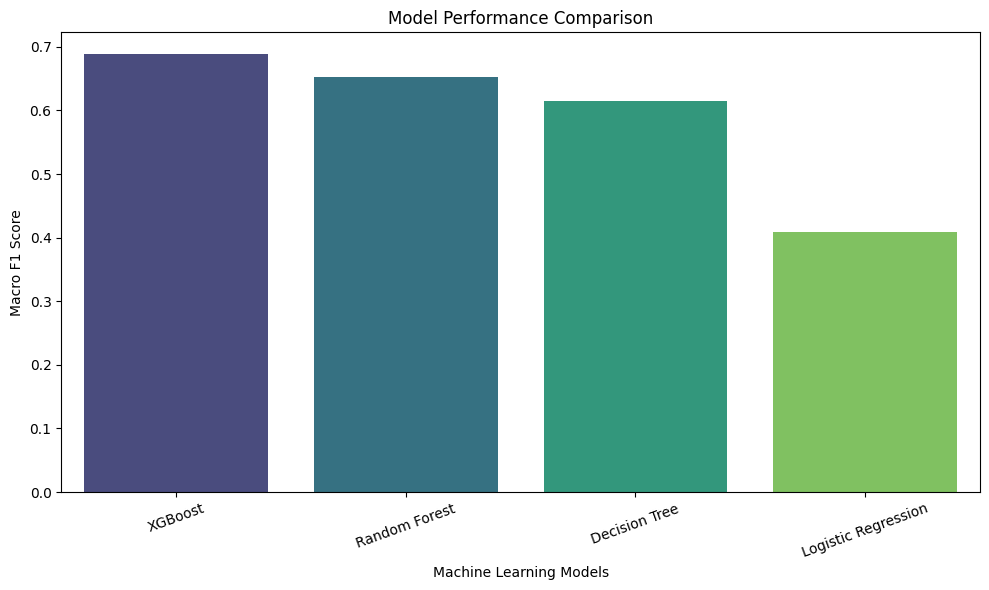

In [24]:
plt.figure(figsize=(10, 6))
sns.barplot(data=comparison_df, x="Model", y="F1 Score", hue="Model",palette="viridis",legend=False)
plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Macro F1 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

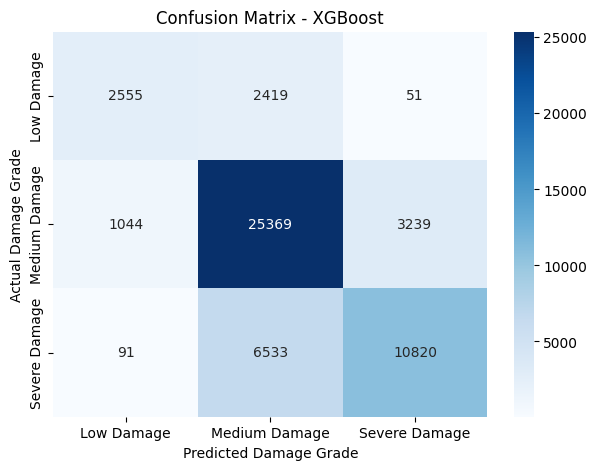

In [25]:
best_model_name = comparison_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]
cm = confusion_matrix(y_test,best_predictions,labels=[1, 2, 3])
plt.figure(figsize=(7, 5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Low Damage","Medium Damage","Severe Damage"],yticklabels=["Low Damage","Medium Damage","Severe Damage"])
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Damage Grade")
plt.ylabel("Actual Damage Grade")
plt.show()

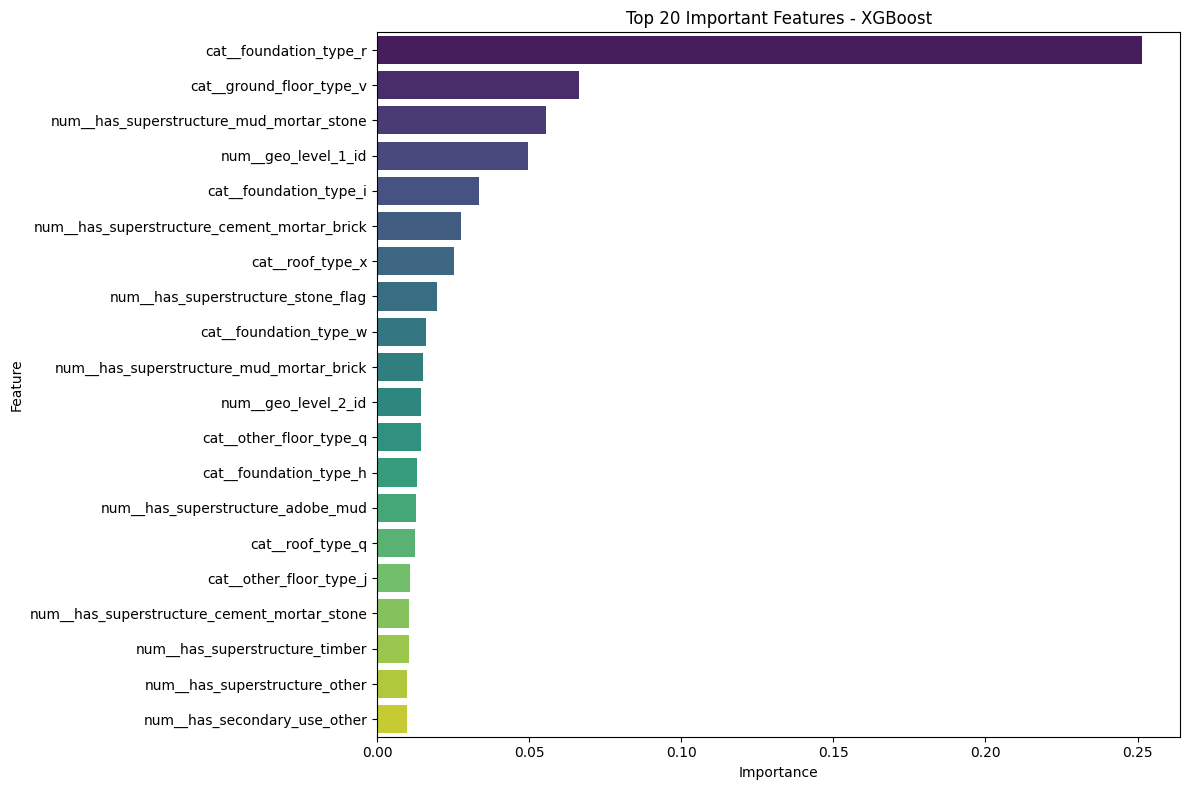

In [26]:
fitted_preprocessor = xgb_model.named_steps["preprocessor"]
fitted_classifier = xgb_model.named_steps["classifier"]
feature_names = fitted_preprocessor.get_feature_names_out()
importance = fitted_classifier.feature_importances_
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importance})
importance_df = importance_df.sort_values(by="Importance",ascending=False).head(20)
plt.figure(figsize=(12, 8))
sns.barplot(data=importance_df,x="Importance",y="Feature",hue="Feature",palette="viridis",legend=False)
plt.title("Top 20 Important Features - XGBoost")
plt.tight_layout()
plt.show()

In [28]:
import joblib
model_objects = {"Logistic Regression": logistic_model,"Decision Tree": decision_tree_model,"Random Forest": random_forest_model,"XGBoost": xgb_model}
best_model = model_objects[best_model_name]
joblib.dump(best_model, "earthquake_damage_model.pkl")
print("Best model:", best_model_name)

Best model: XGBoost
Model saved successfully!


In [29]:
sample_building = X_test.iloc[[0]]
if best_model_name == "XGBoost":
    predicted_grade = best_model.predict(sample_building)[0] + 1
else:
    predicted_grade = best_model.predict(sample_building)[0]
damage_labels = {
    1: "Low Damage",
    2: "Medium Damage",
    3: "Almost Complete Destruction"
}
print("Predicted Damage Grade:", predicted_grade)
print("Predicted Damage Level:",damage_labels[predicted_grade])
print("Actual Damage Grade:",y_test.iloc[0])

Predicted Damage Grade: 2
Predicted Damage Level: Medium Damage
Actual Damage Grade: 3


**RECOMMENDATIONS TO SEISMOLOGISTS**


1. Identify earthquake-prone geographical regions using seismic hazard mapping
2. Encourage earthquake-resistant building designs in high-risk regions.
3. Retrofit vulnerable older buildings, especially schools, hospitals and public infrastructure.
4. Develop early-warning systems and public earthquake preparedness programs.
5. Monitor high-risk buildings and maintain geographical earthquake damage databases.





In [32]:
challenges = pd.DataFrame({
"Challenge": [
"Class Imbalance",
"Categorical Variables",
"High Cardinality",
"Model Overfitting",
"Large Dataset",
"Ordinal Target Variable"
],
"Technique Used": [
"Class weighting and macro F1 evaluation",
"One-Hot Encoding",
"Sparse One-Hot Encoding and unknown-category handling",
"Train-test split and tree depth restrictions",
"Efficient Pandas and Scikit-learn pipelines",
"Quadratic Weighted Kappa and grade-wise evaluation"
],
"Reason": [
"To prevent majority-class performance from hiding poor minority-class predictions",
"To convert categorical values into numerical features",
"To handle geographical IDs and other categories with many unique values",
"To reduce the risk of learning noise from training data",
"To process a large number of building records efficiently",
"To consider the ordered nature of damage grades"
]
})

display(challenges)

,Challenge,Technique Used,Reason
0,Class Imbalance,Class weighting and macro F1 evaluation,To prevent majority-class performance from hid...
1,Categorical Variables,One-Hot Encoding,To convert categorical values into numerical f...
2,High Cardinality,Sparse One-Hot Encoding and unknown-category h...,To handle geographical IDs and other categorie...
3,Model Overfitting,Train-test split and tree depth restrictions,To reduce the risk of learning noise from trai...
4,Large Dataset,Efficient Pandas and Scikit-learn pipelines,To process a large number of building records ...
5,Ordinal Target Variable,Quadratic Weighted Kappa and grade-wise evalua...,To consider the ordered nature of damage grades


In [33]:
print("=" * 60)
print("EARTHQUAKE DAMAGE PREDICTION - FINAL REPORT")
print("=" * 60)
print("\nDataset Information")
print("Total Buildings:", len(df))
print("Total Features:", X.shape[1])
print("Damage Categories:", sorted(y.unique()))
print("\nModel Comparison")
display(comparison_df.round(4))
print("\nRecommended Model:", best_model_name)
best_result = comparison_df.iloc[0]
print("Macro F1 Score:", round(best_result["F1 Score"], 4))
print("Accuracy:", round(best_result["Accuracy"], 4))
print("Quadratic Kappa:", round(best_result["Quadratic Kappa"], 4))
print("\nProject Completed Successfully!")

EARTHQUAKE DAMAGE PREDICTION - FINAL REPORT

Dataset Information
Total Buildings: 260601
Total Features: 38
Damage Categories: [np.int64(1), np.int64(2), np.int64(3)]

Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score,Quadratic Kappa
3,XGBoost,0.7433,0.7328,0.6614,0.6884,0.6090
2,Random Forest,0.6765,0.6285,0.7000,0.6522,0.5804
1,Decision Tree,0.6425,0.5954,0.6847,0.6156,0.5465
0,Logistic Regression,0.4259,0.4076,0.4861,0.4084,0.2216



Recommended Model: XGBoost
Macro F1 Score: 0.6884
Accuracy: 0.7433
Quadratic Kappa: 0.609

Project Completed Successfully!
